In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

FIG_DIR = Path("../static/images/eda")      # charts ahiya save thase (Django pages ma vaparsu)
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv("../dataset/loan_data.csv")
rows_start = len(df)
print("Start rows:", rows_start)

Start rows: 32581


In [2]:
print("Duplicates before:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Duplicates after :", df.duplicated().sum())
print("Rows now         :", len(df))

Duplicates before: 165
Duplicates after : 0
Rows now         : 32416


In [3]:
before = len(df)
df = df[(df["person_age"] <= 100) & (df["person_emp_length"].fillna(0) <= 60)].reset_index(drop=True)
print("Rows removed:", before - len(df))
print("Max age now:", df["person_age"].max(), "| Max emp length now:", df["person_emp_length"].max())

Rows removed: 7
Max age now: 94 | Max emp length now: 41.0


In [4]:
print("Missing before:")
print(df[["person_emp_length", "loan_int_rate"]].isnull().sum())

df["person_emp_length"] = df["person_emp_length"].fillna(df["person_emp_length"].median())
df["loan_int_rate"] = df["loan_int_rate"].fillna(
    df.groupby("loan_grade")["loan_int_rate"].transform("median")
)

print()
print("Missing after:")
print(df.isnull().sum().sum(), "total missing")

Missing before:
person_emp_length     887
loan_int_rate        3094
dtype: int64

Missing after:
0 total missing


In [5]:
num_cols = ["person_age", "person_income", "person_emp_length", "loan_amnt",
            "loan_int_rate", "loan_percent_income", "cb_person_cred_hist_length"]

rows = []
for c in num_cols:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append((c, df[c].min(), df[c].max(), int(((df[c] < low) | (df[c] > high)).sum())))

pd.DataFrame(rows, columns=["Column", "Min", "Max", "IQR outliers"])

,Column,Min,Max,IQR outliers
0,person_age,20.00,94.00,1486
1,person_income,4000.00,2039784.00,1474
2,person_emp_length,0.00,41.00,850
3,loan_amnt,500.00,35000.00,1678
4,loan_int_rate,5.42,23.22,6
5,loan_percent_income,0.00,0.83,649
6,cb_person_cred_hist_length,2.00,30.00,1138


In [6]:
print("Missing values  :", df.isnull().sum().sum())
print("Duplicate rows  :", df.duplicated().sum())
print("Age range       :", df["person_age"].min(), "-", df["person_age"].max())
print("Income min      :", df["person_income"].min(), "(0 thi vadhare hovu joiye)")
print("Target values   :", sorted(df["loan_status"].unique()))
print()
df.dtypes

Missing values  : 0
Duplicate rows  : 0
Age range       : 20 - 94
Income min      : 4000 (0 thi vadhare hovu joiye)
Target values   : [np.int64(0), np.int64(1)]



person_age                      int64
person_income                   int64
person_home_ownership             str
person_emp_length             float64
loan_intent                       str
loan_grade                        str
loan_amnt                       int64
loan_int_rate                 float64
loan_status                     int64
loan_percent_income           float64
cb_person_default_on_file         str
cb_person_cred_hist_length      int64
dtype: object

In [7]:
print("Rows start :", rows_start)
print("Rows final :", len(df))
print("Removed    :", rows_start - len(df))

df.to_csv("../dataset/loan_data_cleaned.csv", index=False)
print("Saved -> dataset/loan_data_cleaned.csv")

Rows start : 32581
Rows final : 32409
Removed    : 172
Saved -> dataset/loan_data_cleaned.csv


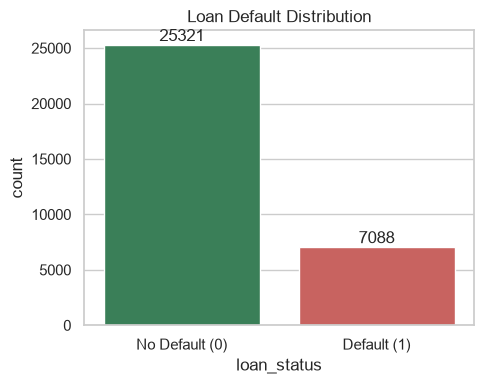

loan_status
0    78.1
1    21.9
Name: proportion, dtype: float64


In [8]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(x="loan_status", data=df, hue="loan_status", palette=["#2e8b57", "#d9534f"], legend=False, ax=ax)
ax.set_xticks([0, 1], ["No Default (0)", "Default (1)"])
ax.set_title("Loan Default Distribution")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_target_distribution.png", dpi=120)
plt.show()

print((df["loan_status"].value_counts(normalize=True) * 100).round(1))

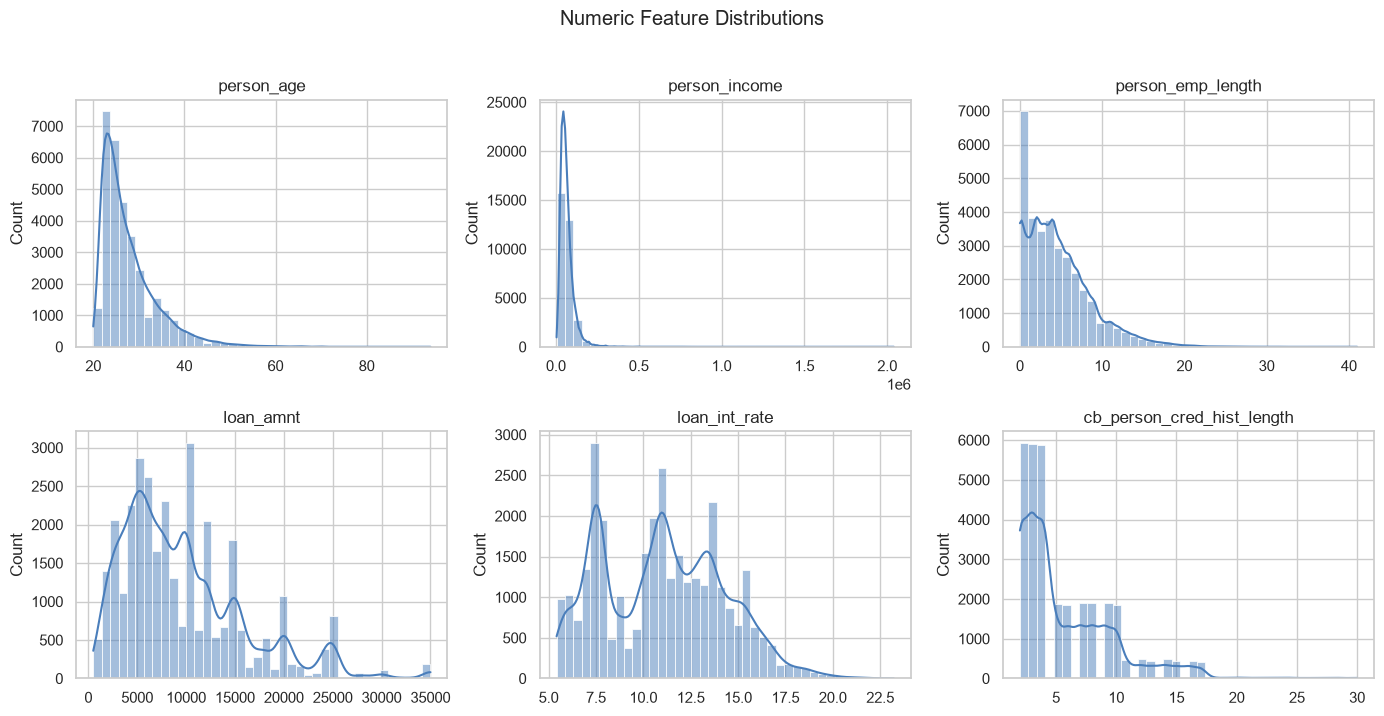

In [9]:
cols = ["person_age", "person_income", "person_emp_length",
        "loan_amnt", "loan_int_rate", "cb_person_cred_hist_length"]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.ravel(), cols):
    sns.histplot(df[c], bins=40, kde=True, ax=ax, color="#4a7ebb")
    ax.set_title(c)
    ax.set_xlabel("")
plt.suptitle("Numeric Feature Distributions", y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "02_numeric_distributions.png", dpi=120, bbox_inches="tight")
plt.show()

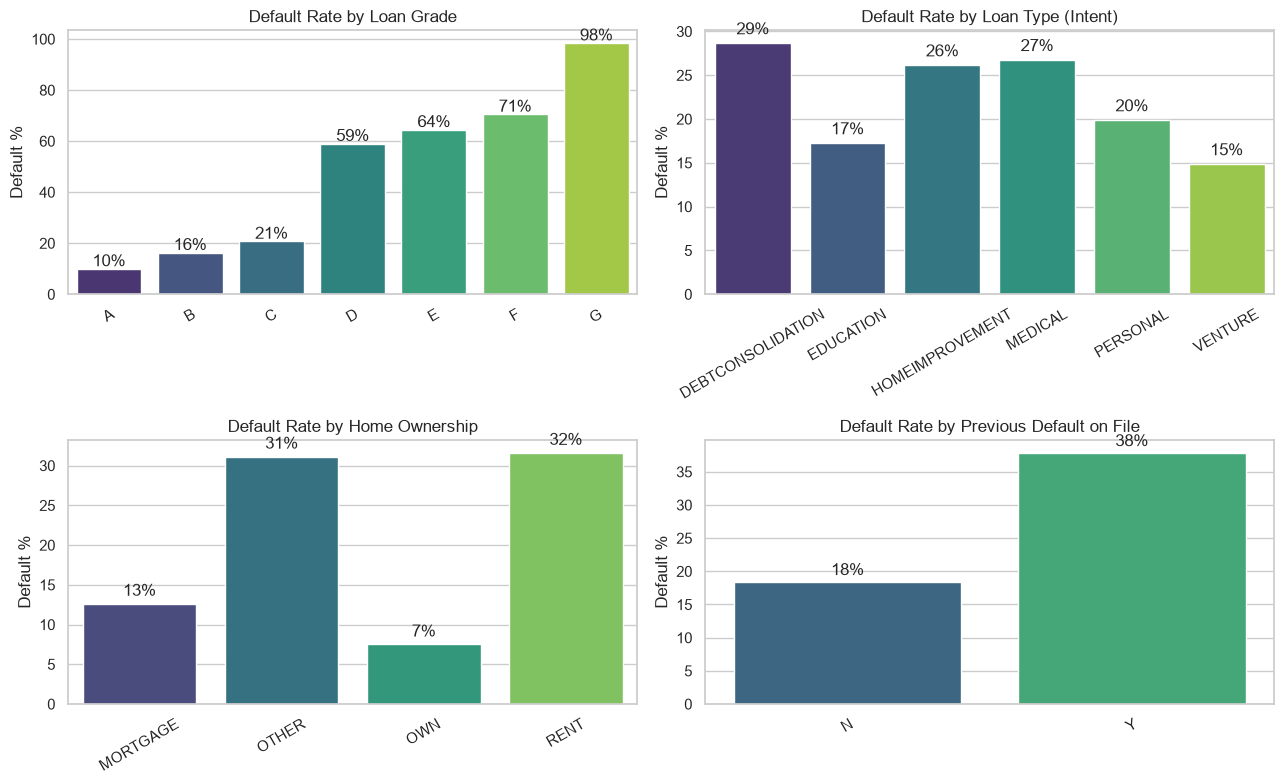

In [10]:
cats = ["loan_grade", "loan_intent", "person_home_ownership", "cb_person_default_on_file"]
titles = ["Loan Grade", "Loan Type (Intent)", "Home Ownership", "Previous Default on File"]

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, c, t in zip(axes.ravel(), cats, titles):
    rate = (df.groupby(c)["loan_status"].mean() * 100).sort_index()
    sns.barplot(x=rate.index, y=rate.values, hue=rate.index, palette="viridis", legend=False, ax=ax)
    ax.set_title(f"Default Rate by {t}")
    ax.set_ylabel("Default %")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
    for i, v in enumerate(rate.values):
        ax.text(i, v + 1, f"{v:.0f}%", ha="center")
plt.tight_layout()
plt.savefig(FIG_DIR / "03_default_rate_by_category.png", dpi=120)
plt.show()

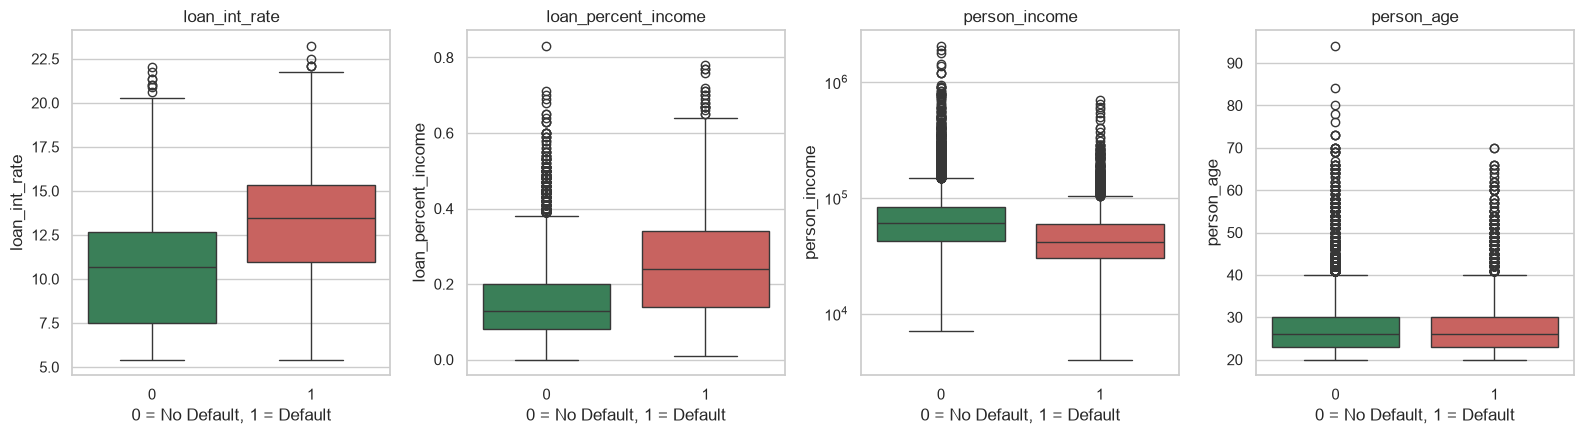

In [11]:
cols = ["loan_int_rate", "loan_percent_income", "person_income", "person_age"]

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, c in zip(axes, cols):
    sns.boxplot(x="loan_status", y=c, data=df, hue="loan_status",
                palette=["#2e8b57", "#d9534f"], legend=False, ax=ax)
    ax.set_title(c)
    ax.set_xlabel("0 = No Default, 1 = Default")
    if c == "person_income":
        ax.set_yscale("log")          # income ma motha values che, etle log scale
plt.tight_layout()
plt.savefig(FIG_DIR / "04_numeric_vs_default.png", dpi=120)
plt.show()

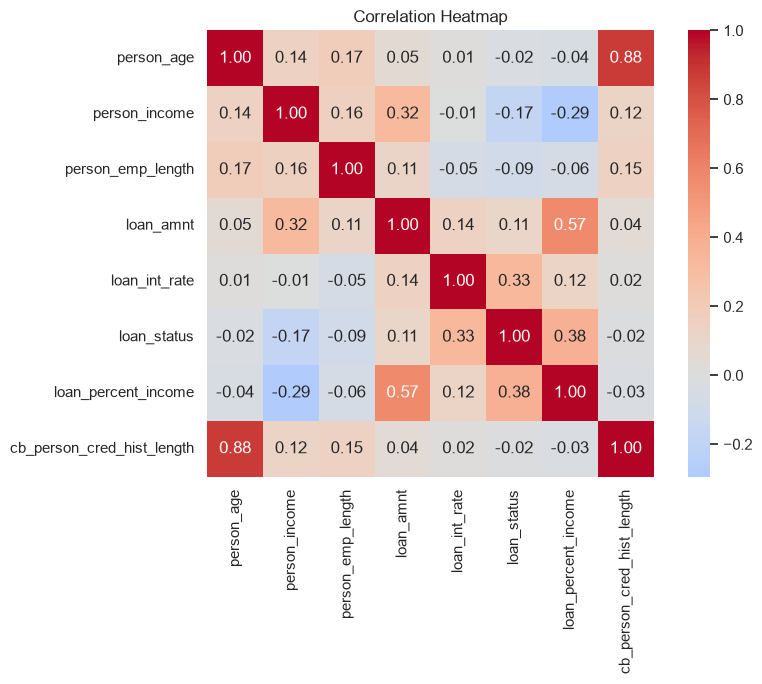

Target sathe correlation:
loan_percent_income           0.380
loan_int_rate                 0.334
loan_amnt                     0.106
cb_person_cred_hist_length   -0.016
person_age                   -0.022
person_emp_length            -0.086
person_income                -0.169
Name: loan_status, dtype: float64


In [12]:
corr = df.select_dtypes(include="number").corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig(FIG_DIR / "05_correlation_heatmap.png", dpi=120)
plt.show()

print("Target sathe correlation:")
print(corr["loan_status"].drop("loan_status").sort_values(ascending=False).round(3))

In [13]:
print(f"Overall default rate: {df['loan_status'].mean() * 100:.1f} %")
print()
for c in cats:
    print(f"--- Default rate by {c} ---")
    print((df.groupby(c)["loan_status"].mean() * 100).round(1).sort_values(ascending=False).to_string())
    print()

Overall default rate: 21.9 %

--- Default rate by loan_grade ---
loan_grade
G    98.4
F    70.5
E    64.5
D    59.0
C    20.8
B    16.3
A    10.0

--- Default rate by loan_intent ---
loan_intent
DEBTCONSOLIDATION    28.7
MEDICAL              26.8
HOMEIMPROVEMENT      26.2
PERSONAL             19.9
EDUCATION            17.3
VENTURE              14.9

--- Default rate by person_home_ownership ---
person_home_ownership
RENT        31.6
OTHER       31.1
MORTGAGE    12.6
OWN          7.5

--- Default rate by cb_person_default_on_file ---
cb_person_default_on_file
Y    37.9
N    18.4

